# DSA 2050 | Data Science Methodology
## Week 6 Guided Practical Lab: Regression and Baseline Comparison

|  **Tools:** Python, Jupyter Notebook, pandas, scikit-learn, matplotlib  |  **Submission:** GitHub

**Student:** Victor Apamo  |  **Student ID:** *673804*


---
# Part 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

> **Why set `RANDOM_STATE`?** Some operations involve randomness (such as the train/test split and tie-breaking in decision trees). A fixed random state makes the split and modelling results reproducible, so anyone re-running this notebook gets the same numbers.

---
# Part 2: Load the Dataset

In [2]:
df = pd.read_csv("DSA2050_Week6_Sales_Data.csv")
df.head()

,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,Sales_KES
0,10801,326,17,Nairobi,SME,Electronics,152376
1,55307,162,23,Nairobi,Retail,Home,119137
2,47547,553,22,Mombasa,Corporate,Office,219441
3,33527,785,12,Nairobi,SME,Electronics,234210
4,33145,830,20,Nairobi,Retail,Home,204277


In [3]:
print("Shape:", df.shape)
print()
df.info()

Shape: (320, 7)

<class 'pandas.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   AdvertisingSpend_KES  320 non-null    int64
 1   StoreVisits           320 non-null    int64
 2   DiscountPercent       320 non-null    int64
 3   Region                320 non-null    str  
 4   CustomerSegment       320 non-null    str  
 5   ProductCategory       320 non-null    str  
 6   Sales_KES             320 non-null    int64
dtypes: int64(4), str(3)
memory usage: 17.6 KB


> **Student check:** state the number of rows and columns, identify numeric and categorical variables, explain what one row represents, and identify the prediction target.

**Answer:**
- **Size:** the dataset has **320 rows and 7 columns**.
- **Numeric variables (4):** `AdvertisingSpend_KES`, `StoreVisits`, `DiscountPercent` and `Sales_KES`.
- **Categorical variables (3):** `Region` (Nairobi, Mombasa, Nakuru, Kisumu), `CustomerSegment` (Retail, SME, Corporate) and `ProductCategory` (Electronics, Office, Accessories, Home).
- **One row represents:** one business sales record: a combination of region, customer segment and product category, with the advertising spend, store visits and discount level recorded for it, and the resulting sales value. (The file does not say whether the unit is a store, a month or a campaign, so I treat each row as one independent sales observation.)
- **Prediction target:** `Sales_KES`, a continuous variable in Kenyan shillings, so this is a regression problem.

---
# Part 3: Basic Data Audit

In [4]:
print("Missing values:")
display(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
display(df.describe(include="all"))

Missing values:


AdvertisingSpend_KES    0
StoreVisits             0
DiscountPercent         0
Region                  0
CustomerSegment         0
ProductCategory         0
Sales_KES               0
dtype: int64

Duplicate rows: 0


,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,Sales_KES
count,320.000000,320.000000,320.000000,320,320,320,320.000000
unique,NaN,NaN,NaN,4,3,4,NaN
top,NaN,NaN,NaN,Nairobi,Retail,Electronics,NaN
freq,NaN,NaN,NaN,139,157,95,NaN
mean,37421.784375,465.440625,12.806250,NaN,NaN,NaN,169252.446875
std,17745.832695,231.651173,7.717583,NaN,NaN,NaN,51968.081691
min,5478.000000,84.000000,0.000000,NaN,NaN,NaN,17805.000000
25%,22985.500000,262.000000,6.000000,NaN,NaN,NaN,131448.750000
50%,37144.000000,461.500000,13.500000,NaN,NaN,NaN,168462.000000
75%,52307.750000,685.500000,20.000000,NaN,NaN,NaN,207050.750000


In [5]:
df["Sales_KES"].describe()

count       320.000000
mean     169252.446875
std       51968.081691
min       17805.000000
25%      131448.750000
50%      168462.000000
75%      207050.750000
max      295825.000000
Name: Sales_KES, dtype: float64

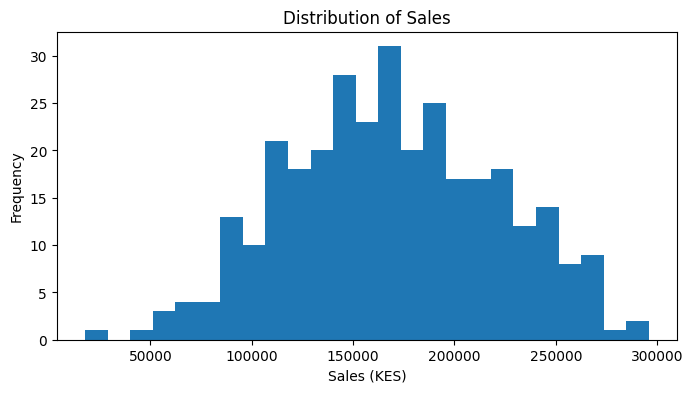

In [6]:
plt.figure(figsize=(8,4))
plt.hist(df["Sales_KES"], bins=25)
plt.title("Distribution of Sales")
plt.xlabel("Sales (KES)")
plt.ylabel("Frequency")
plt.show()

In [7]:
# Supporting check (not removing anything): how extreme is the lowest sales value?
q1, q3 = df["Sales_KES"].quantile([0.25, 0.75])
iqr = q3 - q1
print("IQR fences:", q1 - 1.5 * iqr, "to", q3 + 1.5 * iqr)
print("Values below lower fence:", (df["Sales_KES"] < q1 - 1.5 * iqr).sum())
print("Values above upper fence:", (df["Sales_KES"] > q3 + 1.5 * iqr).sum())
print("Skewness:", round(df["Sales_KES"].skew(), 3))
df.nsmallest(5, "Sales_KES")

IQR fences: 18045.75 to 320453.75
Values below lower fence: 1
Values above upper fence: 0
Skewness: 0.018


,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,Sales_KES
195,10697,161,20,Nairobi,Retail,Home,17805
139,33386,161,22,Nairobi,Retail,Home,48229
110,23012,144,24,Nakuru,SME,Home,58472
253,26440,117,25,Nairobi,Retail,Home,60627
44,9414,169,4,Nairobi,Retail,Home,61119


> **Interpretation:** write 2-3 sentences on the target range, shape, and any unusual values. Do not remove extreme values automatically; first consider whether they may be genuine business cases.

**Answer:** The data is clean: there are **no missing values and no duplicate rows**. `Sales_KES` ranges from KES 17,805 to KES 295,825 with a mean of about KES 169,252 and a median of KES 168,462; the mean and median are nearly equal and the skewness is about 0.02, so the distribution is roughly symmetric and bell-shaped. The only unusual value is a single very low sale of KES 17,805 (just under the lower IQR fence of about 18,046); it is a Nairobi, Retail, Home record with only 161 store visits, so it looks like a genuine low-traffic case rather than an error. I therefore **keep it** rather than deleting it automatically.

---
# Part 4: Define the Analytical Task
- **Business question:** Can available business characteristics be used to estimate sales?
- **Analytical task:** supervised regression.
- **Target:** `Sales_KES`.
- **Features:** `AdvertisingSpend_KES`, `StoreVisits`, `DiscountPercent`, `Region`, `CustomerSegment`, `ProductCategory`.

**Answer:** The business question is predictive: given a record's advertising spend, store traffic, discount, region, customer segment and product category, how closely can we estimate its sales in KES? Because the target is a continuous amount (not a class label), the correct framing is **supervised regression**, and every model must be judged against a simple baseline to show it adds value.

---
# Part 5: Separate Features and Target

In [8]:
X = df.drop(columns="Sales_KES")
y = df["Sales_KES"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape:

 (320, 6)
y shape: (320,)


`X` holds the six predictor columns (320 x 6) and `y` holds the target (320 values). The target is removed from `X` so that the model can never see the answer it is trying to predict.

---
# Part 6: Train/Test Split
Reserve 20% of the data as an untouched final test set. Use the training set for model development and cross-validation. Do not repeatedly use the test set to choose the model.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 256
Test rows: 64


The split gives **256 training rows** and **64 test rows**. The test set stays untouched until models are ready for a final comparison; model development and tuning decisions are made on the training data using cross-validation.

---
# Part 7: Identify Feature Types

In [10]:
numeric_features = [
    "AdvertisingSpend_KES",
    "StoreVisits",
    "DiscountPercent"
]

categorical_features = [
    "Region",
    "CustomerSegment",
    "ProductCategory"
]

Numeric features need imputation and scaling; categorical features need imputation and one-hot encoding. Separating them lets each type receive the right treatment.

---
# Part 8: Leakage-Safe Preprocessing

In [11]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

> **Why use a pipeline?** Learned preprocessing should be fitted only on training data. Keeping preprocessing inside the pipeline helps prevent information leakage during validation.

**Answer:** The imputer medians, scaler means/standard deviations and one-hot categories are all *learned* from data. If they were learned from the full dataset, information from the test rows (or from the validation fold in cross-validation) would leak into training and make results look better than they are. Inside a `Pipeline`, these steps are re-fitted on the training portion only each time `.fit()` is called, and then simply applied to unseen data. (This dataset has no missing values, but the imputers make the pipeline safe for future data that does.)

---
# Part 9: Build Baselines
A baseline gives a minimum reference level. The mean baseline predicts the training-set mean for every case. The median baseline predicts the training-set median.

In [12]:
mean_baseline = DummyRegressor(strategy="mean")
median_baseline = DummyRegressor(strategy="median")

mean_baseline.fit(X_train, y_train)
median_baseline.fit(X_train, y_train)

mean_pred = mean_baseline.predict(X_test)
median_pred = median_baseline.predict(X_test)

In [13]:
print("Mean baseline prediction  :", round(mean_pred[0], 2))
print("Median baseline prediction:", round(median_pred[0], 2))

Mean baseline prediction  : 170141.51
Median baseline prediction: 169335.0


Both baselines ignore every feature and predict a single constant for all customers. Any useful model must beat these.

---
# Part 10: Evaluation Metrics
- **MAE:** average absolute prediction error; lower is better.
- **RMSE:** penalises large errors more heavily than MAE; lower is better.
- **R²:** how much variation in the target is explained by the model; higher is generally better.

In [14]:
def evaluate_regression(y_true, y_pred, name):
    return pd.DataFrame({
        "Model": [name],
        "MAE": [mean_absolute_error(y_true, y_pred)],
        "RMSE": [np.sqrt(mean_squared_error(y_true, y_pred))],
        "R2": [r2_score(y_true, y_pred)]
    })

mean_results = evaluate_regression(y_test, mean_pred, "Mean Baseline")
median_results = evaluate_regression(y_test, median_pred, "Median Baseline")

pd.concat([mean_results, median_results], ignore_index=True)

,Model,MAE,RMSE,R2
0,Mean Baseline,39197.156982,48716.433918,-0.008396
1,Median Baseline,39146.750000,48649.470528,-0.005626


**Answer:** Both baselines have an MAE of about **KES 39,150-39,200** and an RMSE of about **KES 48,700**, with an R² of essentially **zero (slightly negative)**. An R² near zero is expected for a constant prediction: it explains none of the variation in sales. The **median baseline is marginally stronger** than the mean baseline (MAE 39,146.75 vs 39,197.16), though the difference is trivial. This gives a clear target: **a real model must get an MAE well below about KES 39,000.**

---
# Part 11: Linear Regression

In [15]:
linear_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

linear_results = evaluate_regression(
    y_test, linear_pred, "Linear Regression"
)
linear_results

,Model,MAE,RMSE,R2
0,Linear Regression,13757.843478,17469.693466,0.870327


> **Interpretation questions:** Is MAE lower than the baseline? Is RMSE lower? Is R² higher? Does the model add useful predictive value?

**Answer:**
- **MAE lower than baseline?** Yes: about **KES 13,758** versus about 39,150-39,200 for the baselines (roughly a 65% reduction).
- **RMSE lower?** Yes: about **KES 17,470** versus about 48,700.
- **R² higher?** Yes: about **0.870** versus roughly 0.
- **Useful predictive value?** Yes. The model explains about 87% of the variation in sales on unseen data, so the business characteristics carry a lot of information about sales.

---
# Part 12: Ridge Regression

In [16]:
ridge_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)

ridge_results = evaluate_regression(
    y_test, ridge_pred, "Ridge Regression"
)
ridge_results

,Model,MAE,RMSE,R2
0,Ridge Regression,13714.400361,17458.820721,0.870488


> Ridge is linear regression with regularisation. It discourages very large coefficients and can improve stability when predictors are noisy or correlated.

**Answer:** Ridge (alpha = 1.0) gives an MAE of about **KES 13,714**, RMSE of about **17,459** and R² of about **0.8705**, a very slightly better result than plain Linear Regression on all three metrics. The difference is tiny because the data has only a few predictors that are not strongly correlated, so regularisation has little instability to fix. Ridge is still a sensible, safe choice.

---
# Part 13: Shallow Decision Tree

In [17]:
tree_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=4,
        min_samples_leaf=8,
        random_state=RANDOM_STATE
    ))
])

tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)

tree_results = evaluate_regression(
    y_test, tree_pred, "Decision Tree"
)
tree_results

,Model,MAE,RMSE,R2
0,Decision Tree,23775.92494,28767.642109,0.648368


**Answer:** The shallow tree (max depth 4, at least 8 rows per leaf) reaches an MAE of about **KES 23,776**, RMSE of about **28,768** and R² of about **0.648**. It clearly beats the baselines (MAE about 39,150) but is much worse than the linear models. A depth-4 tree can only output at most 16 distinct values, so it cannot follow the smooth, roughly linear way sales rise with store visits and advertising.

---
# Part 14: Compare All Models

In [18]:
comparison = pd.concat([
    mean_results,
    median_results,
    linear_results,
    ridge_results,
    tree_results
], ignore_index=True)

comparison.sort_values("MAE")

,Model,MAE,RMSE,R2
3,Ridge Regression,13714.400361,17458.820721,0.870488
2,Linear Regression,13757.843478,17469.693466,0.870327
4,Decision Tree,23775.924940,28767.642109,0.648368
1,Median Baseline,39146.750000,48649.470528,-0.005626
0,Mean Baseline,39197.156982,48716.433918,-0.008396


> Write a short paragraph: identify the lowest MAE, lowest RMSE, highest R², and the model you would choose from this table alone. Explain why one table is still not enough for a final conclusion.

**Answer:** **Ridge Regression** has the lowest MAE (about 13,714), the lowest RMSE (about 17,459) and the highest R² (about 0.8705), with Linear Regression a very close second, the Decision Tree third, and the two baselines last. From this table alone I would choose **Ridge Regression**. However, one table is not enough for a final conclusion: it is a single score on a single 64-row test set, so the ranking could change with a different split; it says nothing about stability across folds, about *where* the model makes its errors (certain segments, regions or low-sales cases), or about whether the model is overfitting. Cross-validation, residual analysis, subgroup checks and an overfitting check are needed before a recommendation.

---
# Part 15: Cross-Validation on Training Data Only

In [19]:
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

models = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Decision Tree": tree_model
}

rows = []

for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train,
        cv=5,
        scoring=scoring
    )

    rows.append({
        "Model": name,
        "CV_MAE": -scores["test_MAE"].mean(),
        "CV_RMSE": -scores["test_RMSE"].mean(),
        "CV_R2": scores["test_R2"].mean()
    })

cv_results = pd.DataFrame(rows)
cv_results

,Model,CV_MAE,CV_RMSE,CV_R2
0,Linear Regression,15976.774926,20126.771067,0.847517
1,Ridge Regression,15971.368173,20103.541323,0.847907
2,Decision Tree,24498.468304,30608.682961,0.650627


> **Questions:** Which model performs best on average? Are the cross-validation results consistent with the test results? Why is training-data cross-validation safer than repeatedly checking the final test set?

**Answers:**
- **Best on average:** **Ridge Regression** (CV MAE about 15,971, CV RMSE about 20,104, CV R² about 0.848), essentially tied with Linear Regression (CV MAE about 15,977). The Decision Tree is clearly behind (CV MAE about 24,498, CV R² about 0.651).
- **Consistent with the test results?** Yes in *ranking* (Ridge ≈ Linear > Tree), and the tree's R² (about 0.65) matches almost exactly. The absolute errors are somewhat higher in CV (about 16,000 vs about 13,700 on the test set), which suggests this particular 64-row test set was slightly easier than the average fold; this is exactly why a single test score should not be over-trusted.
- **Why training-only CV is safer:** cross-validation repeatedly refits and scores the model on different parts of the *training* data, giving a more stable estimate while the test set stays untouched. If we repeatedly checked the test set to pick models or settings, we would indirectly tune to it, its score would become optimistic, and we would no longer have an honest estimate of performance on truly new data.

---
# Part 16: Residual Analysis
Residual = Actual - Predicted. Positive residuals mean the model under-predicted; negative residuals mean the model over-predicted.

In [20]:
residuals = y_test - linear_pred

residual_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": linear_pred,
    "Residual": residuals.values
})

residual_df.head()

,Actual,Predicted,Residual
0,149359,136532.314107,12826.685893
1,198924,196021.086894,2902.913106
2,152671,143638.944984,9032.055016
3,133621,172495.435274,-38874.435274
4,171171,149069.696640,22101.303360


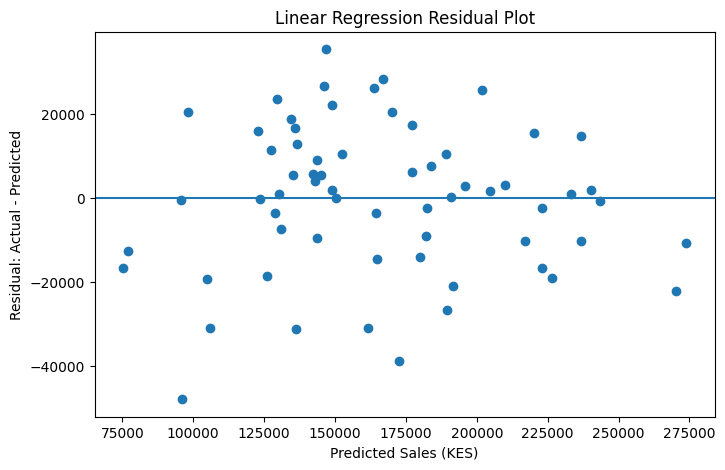

In [21]:
plt.figure(figsize=(8,5))
plt.scatter(linear_pred, residuals)
plt.axhline(0)
plt.title("Linear Regression Residual Plot")
plt.xlabel("Predicted Sales (KES)")
plt.ylabel("Residual: Actual - Predicted")
plt.show()

In [22]:
# Supporting summary of the residuals
print("Mean residual :", round(residuals.mean(), 2))
print("Std of residual:", round(residuals.std(), 2))
print("Min residual  :", round(residuals.min(), 2))
print("Max residual  :", round(residuals.max(), 2))

Mean residual : -337.25
Std of residual: 17604.51
Min residual  : -47859.85
Max residual  : 35378.88


> **Interpretation:** discuss whether residuals are centred around zero, whether a pattern is visible, and whether large residuals exist.

**Answer:** The residuals are **centred around zero**: the mean residual is only about KES -337, so the model is not systematically over- or under-predicting overall. The scatter looks fairly random, with no strong curve or obvious funnel, which supports the use of a linear model; however, the spread is not perfectly even (the residual standard deviation is about KES 17,600) and there are a few **large residuals**, the biggest being an over-prediction of about KES 47,900 and an under-prediction of about KES 35,400. Those are the cases to examine in Part 18.

---
# Part 17: Actual vs Predicted

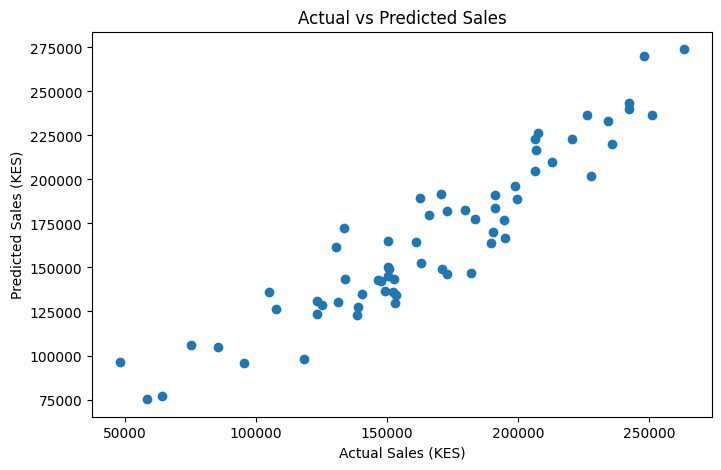

In [23]:
plt.figure(figsize=(8,5))
plt.scatter(y_test, linear_pred)
plt.title("Actual vs Predicted Sales")
plt.xlabel("Actual Sales (KES)")
plt.ylabel("Predicted Sales (KES)")
plt.show()

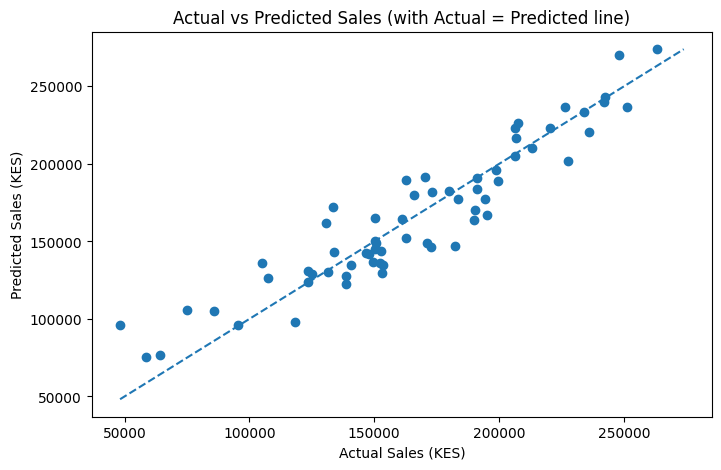

Correlation (actual, predicted): 0.933


In [24]:
# Add the Actual = Predicted reference line and quantify the fit
lims = [min(y_test.min(), linear_pred.min()), max(y_test.max(), linear_pred.max())]
plt.figure(figsize=(8,5))
plt.scatter(y_test, linear_pred)
plt.plot(lims, lims, linestyle="--")
plt.title("Actual vs Predicted Sales (with Actual = Predicted line)")
plt.xlabel("Actual Sales (KES)")
plt.ylabel("Predicted Sales (KES)")
plt.show()

print("Correlation (actual, predicted):", round(np.corrcoef(y_test, linear_pred)[0, 1], 3))

> If predictions were perfect, points would lie close to an imaginary diagonal line where Actual = Predicted.

**Answer:** The points follow the diagonal closely (correlation about 0.93), consistent with the R² of about 0.87. A handful of points sit noticeably away from the line, especially at the low-sales end where the model tends to predict more than was actually sold; these are the large negative residuals seen above.

---
# Part 18: Inspect Largest Errors

In [25]:
error_analysis = X_test.copy()
error_analysis["ActualSales"] = y_test
error_analysis["PredictedSales"] = linear_pred
error_analysis["Residual"] = (
    error_analysis["ActualSales"] - error_analysis["PredictedSales"]
)
error_analysis["AbsoluteError"] = error_analysis["Residual"].abs()

error_analysis.sort_values(
    "AbsoluteError", ascending=False
).head(10)

,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,ActualSales,PredictedSales,Residual,AbsoluteError
139,33386,161,22,Nairobi,Retail,Home,48229,96088.854657,-47859.854657,47859.854657
63,67888,265,4,Nakuru,SME,Accessories,133621,172495.435274,-38874.435274,38874.435274
46,33969,441,10,Nakuru,Retail,Accessories,182186,146807.115940,35378.884060,35378.884060
7,50328,108,13,Nairobi,Retail,Electronics,104994,136091.949761,-31097.949761,31097.949761
5,60808,257,8,Nairobi,Retail,Accessories,130757,161701.195990,-30944.195990,30944.195990
76,26462,114,13,Nairobi,Retail,Electronics,75103,106000.271668,-30897.271668,30897.271668
260,56576,151,0,Nairobi,Corporate,Home,195145,166919.218106,28225.781894,28225.781894
226,57562,410,21,Kisumu,Corporate,Office,162770,189424.021603,-26654.021603,26654.021603
73,13444,541,19,Nakuru,Retail,Electronics,172866,146216.703107,26649.296893,26649.296893
297,33529,285,3,Nairobi,Corporate,Office,189884,163816.773893,26067.226107,26067.226107


In [26]:
# Supporting check: do the largest errors share low store traffic?
top10 = error_analysis.sort_values("AbsoluteError", ascending=False).head(10)
print("Mean StoreVisits, top-10 errors :", round(top10["StoreVisits"].mean(), 1))
print("Mean StoreVisits, all test rows :", round(error_analysis["StoreVisits"].mean(), 1))
print("Top-10 errors that are over-predictions (negative residual):", (top10["Residual"] < 0).sum())

error_analysis["LowVisits(<300)"] = error_analysis["StoreVisits"] < 300
error_analysis.groupby("LowVisits(<300)").agg(
    Observations=("AbsoluteError", "size"),
    MAE=("AbsoluteError", "mean"),
    MeanResidual=("Residual", "mean")
)

Mean StoreVisits, top-10 errors :

 273.3
Mean StoreVisits, all test rows : 432.1
Top-10 errors that are over-predictions (negative residual): 6


,Observations,MAE,MeanResidual
LowVisits(<300),,,
False,41,10659.442423,1669.316187
True,23,19281.080143,-3914.183392


> **Questions:** Do the largest errors share characteristics? Are they concentrated in one region, segment, or category? What additional data might explain them?

**Answers:**
- **Shared characteristics:** yes, partly. The ten largest errors have much lower store traffic (average about 273 visits versus about 432 for all test rows), and 7 of the 10 have fewer than 300 visits. Six of the ten are **over-predictions**. Test rows with fewer than 300 visits have an MAE of about KES 19,300 versus about KES 10,700 for the rest, and they are over-predicted on average (mean residual about -3,900). In other words, the linear model struggles most at the low-traffic end, where actual sales fall faster than a straight line predicts.
- **Concentration:** no single group fully explains them. Six of the ten are in Nairobi, but Nairobi is also the largest region in the test set (28 of 64 rows), and six are Retail (Retail is 27 of 64 rows), so these shares are not far above what we would expect by chance. The errors are spread across all categories.
- **Additional data that might help:** store size or format, local foot-traffic quality, promotion timing, seasonality or month, stock availability, competitor activity, and customer-level history (repeat vs new customers).

---
# Part 19: Error by Customer Segment

In [27]:
segment_errors = error_analysis.groupby(
    "CustomerSegment"
).agg(
    Observations=("AbsoluteError", "size"),
    MAE=("AbsoluteError", "mean")
).reset_index()

segment_errors

,CustomerSegment,Observations,MAE
0,Corporate,19,14300.002844
1,Retail,27,15560.578163
2,SME,18,10481.462121


> Explain which segment has the highest MAE, whether sample sizes are similar, and why subgroup performance matters even when overall MAE looks acceptable.

**Answer:** **Retail** has the highest MAE (about KES 15,561), followed by Corporate (about 14,300) and SME (about 10,481), which is the best predicted. The sample sizes are **not equal**: Retail has 27 test rows, Corporate 19 and SME 18, so each segment MAE rests on a small number of rows and the differences could partly be noise. Subgroup performance matters because an acceptable overall MAE (about 13,758) can hide groups where the model is noticeably worse; Retail is both the largest segment and the least accurately predicted, so any decisions made for Retail would rest on weaker estimates. Checking subgroups helps ensure the model is reliable and fair across the business, not only on average.

---
# Part 20: Check for Overfitting

In [28]:
tree_train_pred = tree_model.predict(X_train)

print(
    "Shallow Tree Training MAE:",
    round(mean_absolute_error(y_train, tree_train_pred), 2)
)

print(
    "Shallow Tree Test MAE:",
    round(mean_absolute_error(y_test, tree_pred), 2)
)

Shallow Tree Training MAE: 18029.7
Shallow Tree Test MAE: 23775.92


In [29]:
# For context: the linear model's train vs test MAE
linear_train_pred = linear_model.predict(X_train)
print("Linear Training MAE:", round(mean_absolute_error(y_train, linear_train_pred), 2))
print("Linear Test MAE    :", round(mean_absolute_error(y_test, linear_pred), 2))

Linear Training MAE: 15096.52
Linear Test MAE    : 13757.84


**Answer:** The shallow tree has a training MAE of about **KES 18,030** and a test MAE of about **KES 23,776**; the test error is roughly 32% higher, so there is a **mild overfitting gap**, though the tree is constrained enough that it is not severe. By contrast, the linear model has a training MAE of about 15,097 and a test MAE of about 13,758, with no sign of overfitting (the test error is not worse than the training error).

---
# Part 21: Demonstrate an Overly Deep Tree

In [30]:
deep_tree = Pipeline([
    ("preprocess", preprocessor),
    ("model", DecisionTreeRegressor(
        random_state=RANDOM_STATE
    ))
])

deep_tree.fit(X_train, y_train)

deep_train_pred = deep_tree.predict(X_train)
deep_test_pred = deep_tree.predict(X_test)

print(
    "Deep Tree Training MAE:",
    round(mean_absolute_error(y_train, deep_train_pred), 2)
)

print(
    "Deep Tree Test MAE:",
    round(mean_absolute_error(y_test, deep_test_pred), 2)
)

Deep Tree Training MAE: 0.0
Deep Tree Test MAE: 26797.5


> Explain why an almost-perfect training result does not necessarily indicate a better model.

**Answer:** The unrestricted tree has a training MAE of **0.0** (it memorises every training row) but a test MAE of about **KES 26,798**, which is worse than the shallow tree (about 23,776) and far worse than the linear models (about 13,700). A perfect training score only shows the model has fitted the training data, including its noise; what matters is performance on data it has not seen. A large gap between training and test error is the classic signature of **overfitting**, so a model should be judged on held-out or cross-validated performance, not on how well it fits the training set.

---
# Part 22: Extension Challenge
Choose ONE:
- Try Decision Tree `max_depth` values 2, 4, 6, and None and compare test MAE.
- Try Ridge `alpha` values 0.1, 1, 10, and 100.
- **Remove `AdvertisingSpend_KES` or `StoreVisits`, retrain Linear Regression, and explain the performance change.** *(chosen option)*

I chose the third option because it shows which predictors the model depends on most. I removed each variable in turn and retrained Linear Regression with the same split and pipeline.

In [31]:
def run_linear_without(drop_col):
    num_cols = [c for c in numeric_features if c != drop_col]
    pre = ColumnTransformer([
        ("num", numeric_pipeline, num_cols),
        ("cat", categorical_pipeline, categorical_features)
    ])
    model = Pipeline([("preprocess", pre), ("model", LinearRegression())])
    model.fit(X_train.drop(columns=drop_col), y_train)
    pred = model.predict(X_test.drop(columns=drop_col))
    return evaluate_regression(y_test, pred, f"Linear without {drop_col}")

extension_results = pd.concat([
    linear_results.assign(Model="Linear (all features)"),
    run_linear_without("AdvertisingSpend_KES"),
    run_linear_without("StoreVisits"),
    median_results
], ignore_index=True)

extension_results

,Model,MAE,RMSE,R2
0,Linear (all features),13757.843478,17469.693466,0.870327
1,Linear without AdvertisingSpend_KES,21432.037335,27065.724576,0.688743
2,Linear without StoreVisits,34428.077412,42291.400487,0.240051
3,Median Baseline,39146.750000,48649.470528,-0.005626


In [32]:
# Standardised coefficients of the full linear model (effect of +1 standard deviation / category)
feature_names = linear_model.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(linear_model.named_steps["model"].coef_, index=feature_names)
coefs.sort_values(key=abs, ascending=False).round(0)

num__StoreVisits                    38757.0
num__AdvertisingSpend_KES           23323.0
cat__CustomerSegment_Corporate      14414.0
cat__ProductCategory_Electronics    12166.0
cat__CustomerSegment_Retail        -10148.0
cat__ProductCategory_Home           -7315.0
cat__Region_Nairobi                  6976.0
num__DiscountPercent                -6211.0
cat__Region_Kisumu                  -4969.0
cat__ProductCategory_Accessories    -4632.0
cat__CustomerSegment_SME            -4266.0
cat__Region_Nakuru                  -1885.0
cat__ProductCategory_Office          -220.0
cat__Region_Mombasa                  -123.0
dtype: float64

**Answer:**
- **Removing `AdvertisingSpend_KES`:** MAE rises from about 13,758 to about **KES 21,432** (R² falls from about 0.870 to about 0.689). The model still beats the baseline (about 39,150), but advertising clearly carries useful signal.
- **Removing `StoreVisits`:** MAE rises sharply to about **KES 34,428** (R² collapses to about 0.240), which is only slightly better than the baseline. `StoreVisits` is the most important predictor by far.
- **Supporting evidence:** this agrees with the standardised coefficients: `StoreVisits` has the largest effect (about +38,757 KES per standard deviation), then `AdvertisingSpend_KES` (about +23,323), with `DiscountPercent` having a smaller, negative coefficient (about -6,211).
- **Caution:** the coefficients and this comparison show *predictive association*, not causation (for example, store visits may rise *because* of higher demand, not cause it). Also, this extension uses the test set for exploration only; it is not used to select the final model.

---
# Part 23: Final Recommendation
Write 6-8 sentences answering: Which baseline was strongest? Which candidate model performed best? Did it clearly beat the baseline? What does MAE mean in business terms? What did residual analysis reveal? Did performance differ by customer segment? Is there evidence of overfitting? Would you deploy the model immediately? Why or why not?

**Answer:**

The **median baseline** was marginally the strongest baseline (test MAE about KES 39,147 versus 39,197 for the mean), although both had an R² of roughly zero. **Ridge Regression** performed best, with a test MAE of about KES 13,714, RMSE of about 17,459 and R² of about 0.87, and its cross-validated MAE (about KES 15,971) confirmed the same ranking, with Linear Regression nearly identical and the Decision Tree well behind. It **clearly beat the baseline**, cutting average error by about 65%. In business terms, a typical prediction is off by roughly **KES 14,000-16,000, or about 8-10% of average sales** (mean sales are about KES 169,000), which is useful for planning but not exact. Residual analysis showed errors centred near zero with no strong pattern, but the model **over-predicts sales when store traffic is low** (rows with fewer than 300 visits have a much higher MAE), and performance differed by segment, with Retail (MAE about 15,561) worse than SME (about 10,481), although the segment samples are small. There is **no meaningful overfitting** in the linear models (test error is not above training error), whereas the shallow tree shows a mild gap and the unrestricted tree overfits badly (training MAE 0 versus test MAE about 26,800). I would **not deploy the model immediately**: the dataset is small (320 rows) and looks like teaching data, the model is weakest in low-traffic cases that may matter most, and it has not been tested on newer data or monitored for drift. I would recommend a **supervised pilot**, using the model to support (not replace) human planning while collecting more data and the additional variables suggested in Part 18.

---
# Part 24: Limitations
State at least three limitations.

1. **Small dataset.** Only 320 rows (256 for training and just 64 for testing), so the metrics are noisy: the test MAE (about 13,700) was noticeably lower than the cross-validated MAE (about 16,000), and segment-level results rest on only 18-27 rows each.
2. **Teaching / synthetic-looking data.** The data appears to be prepared for a class exercise (clean, complete, no missing values or duplicates), so real business data would likely be messier and the model's accuracy would probably be lower.
3. **Limited predictors and missing external factors.** Only six variables are used. There is no information on time or seasonality, store size, pricing, competitors, stock availability or economic conditions, which probably explain part of the large errors at low store traffic.
4. **No time dimension / future data drift.** Rows are split randomly, not by date, so we cannot tell how the model would perform on future periods if customer behaviour or the market changes.
5. **Association, not causation.** The model predicts sales from patterns in the data; it does not prove that raising advertising or store visits *causes* higher sales, and it should not be used alone to justify spending decisions.
6. **Linear assumptions and uneven subgroups.** The linear model assumes straight-line effects (it over-predicts in low-traffic cases), and the segment, region and category groups are small and unequal, so subgroup conclusions are tentative.

---
# Summary of Results
| Model | Test MAE (KES) | Test RMSE (KES) | Test R² | CV MAE (KES) |
|---|---:|---:|---:|---:|
| Mean Baseline | 39,197 | 48,716 | -0.008 | n/a |
| Median Baseline | 39,147 | 48,649 | -0.006 | n/a |
| Linear Regression | 13,758 | 17,470 | 0.870 | 15,977 |
| **Ridge Regression (alpha = 1)** | **13,714** | **17,459** | **0.870** | **15,971** |
| Decision Tree (depth 4) | 23,776 | 28,768 | 0.648 | 24,498 |

**Selected model:** Ridge Regression, test MAE about KES 13,714.